# Clearance estimation at scale: MapAnything (+ automatic segmentation) vs. ground truth

Extends `kely_sam3-mapanything` (single IDOT gantry, no GT) and `restart-Mapanything` (manual clicks) to **many Mapillary sequences with official ground truth**.

> SAM3 is gated (access pending), so automatic point selection here uses **Mask2Former Swin-L trained on Mapillary Vistas** (`facebook/mask2former-swin-large-mapillary-vistas-semantic`, open). It has street-level classes such as *Bridge*, *Road*, *Lane Marking*, *Traffic Sign (Front)*. The function keeps the name `sam3_segment`, so swapping SAM3 back in later means changing only that function.

**Experiment A: bridge under-clearance (main).** GT = FHWA *National Bridge Inventory* (Illinois 2025) `VERT_CLR_UND_054B`, the inspected **minimum vertical under-clearance (m)** for bridges with a highway beneath (`054A = 'H'`). Chicago-metro bridges are de-duplicated and ordered round-robin across clearance bins × structure type (street over interstate, interstate over street, CTA/rail viaducts, interchange ramps).
For each bridge, 8 Mapillary frames from one sequence that is heading toward it (perspective cameras, 12–140 m). Mask2Former then picks the **anchor frame** where the overhead structure is seen best, plus the 3 nearest frames for MapAnything multi-view.
**Clearance = distance from structure-underside 3D points to a RANSAC road plane**, as the median over image columns. Only underside points **above the camera** are kept, which removes walls, abutments and barriers. Single-view and multi-view runs are both reported, along with the old point-to-point metric. **Auto-QC** (no GT used) checks for a recovered camera height of 0.7–3.5 m, at least 10 columns, and a structure within 90 m.

**Experiment B: stop-sign size.** Mapillary `map_features` gives detected R1-1 stop signs and the images that see them. Size = sign pixel width × MapAnything depth / focal length. GT = MUTCD standard 30" (0.762 m), or 36" (0.914 m) on multi-lane approaches.

All outputs go to `MyDrive/capstone_clearance_nbi/` and every case is cached. After a Colab disconnect, re-run cells 0 → 7 (+ 10/11) and finished cases load from Drive.

In [ ]:
# =========================
# 0. Install SAM3 + MapAnything (run once per runtime; auto-restarts the session after a fresh install)
# =========================
import os, sys, subprocess
from pathlib import Path

MARKER = Path("/content/.clearance_env_ready")
print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv"], capture_output=True, text=True).stdout)

if not MARKER.exists() or not Path("/content/.numpy2_fixed").exists():
    if not Path("/content/map-anything").exists():
        !git clone -q https://github.com/facebookresearch/map-anything.git /content/map-anything
    if not Path("/content/sam3").exists():
        !git clone -q https://github.com/facebookresearch/sam3.git /content/sam3
    !pip install -q -e /content/map-anything
    !pip install -q -e /content/sam3
    !pip install -q plotly opencv-python-headless einops pycocotools decord psutil
    # sam3 pins numpy<2, which breaks Colab's numpy-2 builds (matplotlib/contourpy, opencv); restore numpy 2.x
    !pip install -q "numpy>=2.0,<2.4"
    MARKER.write_text("ok"); Path("/content/.numpy2_fixed").write_text("ok")
    print("Installed. Restarting the Python session so new packages load cleanly ...")
    os.kill(os.getpid(), 9)
else:
    print("Environment already installed:", MARKER)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB

  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 130.4 MB/s eta 0:00:00
  Building editable for mapanything (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sam3 0.1.0 requires numpy<2,>=1.26, but you have numpy 2.5.3 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.3 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for sam3 (pyproject.toml) ..

In [6]:
# =========================
# 2. Ground truth: FHWA National Bridge Inventory (Illinois)
#    VERT_CLR_UND_054B = minimum vertical under-clearance (m), VERT_CLR_UND_REF_054A = 'H' -> highway beneath
# =========================
NBI_PATH = OUT_ROOT / "IL_nbi.txt"
if not NBI_PATH.exists():
    for year in [2025, 2024, 2023]:
        url = f"https://www.fhwa.dot.gov/bridge/nbi/{year}/delimited/IL{str(year)[2:]}.txt"
        r = requests.get(url, timeout=120)
        if r.ok:
            NBI_PATH.write_bytes(r.content); print("NBI downloaded:", url); break
nbi = pd.read_csv(NBI_PATH, dtype=str, quotechar="'", on_bad_lines="skip")

def nbi_dms(s, west=False):
    s = str(s).strip()
    if not s.isdigit():
        return np.nan
    s = s.zfill(9 if west else 8)
    v = int(s[:-6]) + int(s[-6:-4]) / 60 + int(s[-4:]) / 100 / 3600
    return -v if west else v

SERVICE_ON = {"1": "highway", "2": "railroad", "3": "pedestrian", "4": "highway-railroad",
              "5": "highway-pedestrian", "6": "interchange overpass", "7": "3rd-level interchange",
              "8": "4th-level interchange", "9": "building/plaza", "0": "other"}
STRUCT_KIND = {"1": "concrete", "2": "concrete continuous", "3": "steel", "4": "steel continuous",
               "5": "prestressed concrete", "6": "prestressed concrete continuous", "7": "wood",
               "8": "masonry", "9": "aluminum/iron", "0": "other"}

nbi["lat"] = nbi["LAT_016"].apply(nbi_dms)
nbi["lon"] = nbi["LONG_017"].apply(lambda s: nbi_dms(s, west=True))
nbi["gt_clearance_m"] = pd.to_numeric(nbi["VERT_CLR_UND_054B"], errors="coerce")
gt = nbi[
    (nbi["VERT_CLR_UND_REF_054A"] == "H")
    & nbi["gt_clearance_m"].between(GT_MIN_M, GT_MAX_M)
    & nbi["lat"].between(REGION_BBOX["lat_min"], REGION_BBOX["lat_max"])
    & nbi["lon"].between(REGION_BBOX["lon_min"], REGION_BBOX["lon_max"])
].copy()
gt["service_on"] = gt["SERVICE_ON_042A"].map(SERVICE_ON).fillna("other")
gt["structure_kind"] = gt["STRUCTURE_KIND_043A"].map(STRUCT_KIND).fillna("other")
gt["year_built"] = gt["YEAR_BUILT_027"]
gt = gt.rename(columns={"STRUCTURE_NUMBER_008": "structure_number", "FEATURES_DESC_006A": "feature_under",
                        "FACILITY_CARRIED_007": "facility_on", "LOCATION_009": "nbi_location"})
gt["structure_number"] = gt["structure_number"].str.strip()

# de-duplicate twin structures (NB/SB decks) closer than 60 m
gt = gt.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
kept = []
for i, r in gt.iterrows():
    if all(haversine_m(r.lon, r.lat, k.lon, k.lat) > 60 for k in kept):
        kept.append(r)
gt = pd.DataFrame(kept).reset_index(drop=True)

# stratified ordering: round-robin over clearance bins x service type -> diverse cases first
gt["clr_bin"] = pd.cut(gt["gt_clearance_m"], [0, 4.45, 4.75, 5.2, 6.0, 99], labels=["<4.45", "4.45-4.75", "4.75-5.2", "5.2-6", ">6"])
gt["stratum"] = gt["clr_bin"].astype(str) + "|" + gt["service_on"]
gt["rank_in_stratum"] = gt.groupby("stratum").cumcount()
gt = gt.sort_values(["rank_in_stratum", "stratum"]).reset_index(drop=True)
keep_cols = ["structure_number", "feature_under", "facility_on", "nbi_location", "lat", "lon", "gt_clearance_m",
             "service_on", "structure_kind", "year_built", "clr_bin", "stratum"]
gt = gt[keep_cols]
gt.to_csv(OUT_ROOT / "nbi_gt_candidates.csv", index=False)
print("NBI bridges with highway beneath (deduped, Chicago metro):", len(gt))
display(gt["stratum"].value_counts().head(15))
display(gt.head(10))

NBI downloaded: https://www.fhwa.dot.gov/bridge/nbi/2025/delimited/IL25.txt
NBI bridges with highway beneath (deduped, Chicago metro): 523


,count
stratum,
<4.45|interchange overpass,91
4.75-5.2|highway,85
<4.45|highway,82
4.45-4.75|highway,79
4.45-4.75|interchange overpass,78
4.75-5.2|interchange overpass,65
5.2-6|highway,16
>6|highway,13
5.2-6|interchange overpass,6


,structure_number,feature_under,facility_on,nbi_location,lat,lon,gt_clearance_m,service_on,structure_kind,year_built,clr_bin,stratum
0,016261000000000,I-294 TRI STATE TOLL,55TH ST,2.1 M W OF US 45,41.789606,-87.908217,4.65,highway,prestressed concrete continuous,1992,4.45-4.75,4.45-4.75|highway
1,049017000000000,US 45,IL 137,1.4 M S OF IL 120,42.314550,-88.004389,4.57,interchange overpass,steel continuous,1993,4.45-4.75,4.45-4.75|interchange overpass
2,099018800000000,I- 80,CENTER ST NB,1.0 M W OF IL-53,41.512483,-88.098697,5.00,3rd-level interchange,steel continuous,1965,4.75-5.2,4.75-5.2|3rd-level interchange
3,016256100000000,IL 390 ELGIN-OHARE,ROSELLE RD,3.8 M W I-290,41.994542,-88.080325,5.00,highway,steel continuous,1991,4.75-5.2,4.75-5.2|highway
4,099033300000000,I-355,IL 171,0.62 M S OF 139TH ST,41.632450,-88.014708,4.98,interchange overpass,prestressed concrete continuous,2007,4.75-5.2,4.75-5.2|interchange overpass
5,016106200000000,ARCHER BNSF & IC RR,I- 90 94 SB TOI-55,0.1 M W I-94,41.850228,-87.644983,5.49,3rd-level interchange,steel continuous,1964,5.2-6,5.2-6|3rd-level interchange
6,016617800000000,N. ST. CLAIR STREET,ILLINOIS ST,500N-300E TO 200E,41.890989,-87.623572,5.44,highway,steel continuous,2005,5.2-6,5.2-6|highway
7,016037400000000,US 14 NW HWY & UP RR,IL 53 NB,1 M S PALATINE RD,42.100469,-88.019972,5.49,interchange overpass,steel continuous,1964,5.2-6,5.2-6|interchange overpass
8,016984100000000,115TH ST,I-294 NB,1.5 M S ILL 7 P26,41.683214,-87.779642,4.34,highway,prestressed concrete,1958,<4.45,<4.45|highway
9,016051800000000,US 12 20 45 MANNHEIM,IL 171 & 79 ST EB,0.1 M SW US 45,41.745461,-87.852700,4.27,interchange overpass,steel,1959,<4.45,<4.45|interchange overpass


In [22]:
# =========================
# 1. Config, Drive output folder, tokens, Mapillary helpers
# =========================
import os, sys, json, math, time, gc, traceback, warnings
from pathlib import Path
from io import BytesIO
import numpy as np
import pandas as pd
import requests
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display
from google.colab import drive, userdata

warnings.filterwarnings("ignore")
for p in ["/content/map-anything", "/content/sam3"]:
    if p not in sys.path:
        sys.path.insert(0, p)

if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")
def _secret(*names):
    for n in names:
        try:
            v = userdata.get(n)
            if v: return v.strip()
        except Exception:
            pass
    raise RuntimeError(f"Add one of {names} in Colab Secrets (key icon) with notebook access ON")
os.environ.setdefault("MAPILLARY_TOKEN", _secret("MAPILLARY_TOKEN"))
os.environ.setdefault("HF_TOKEN", _secret("HF_TOKEN", "HK_TOKEN", "HUGGINGFACE_TOKEN"))
MAPILLARY_TOKEN = os.environ["MAPILLARY_TOKEN"]
from huggingface_hub import login
try:
    login(token=os.environ["HF_TOKEN"], add_to_git_credential=False); print("HF login OK")
except Exception as e:
    print("!! HF login failed (SAM3 checkpoint download will fail):", str(e)[:120])
    os.environ.pop("HF_TOKEN", None)  # an invalid token would also block public downloads (MapAnything)

# ---- output folders (on Drive, so a Colab disconnect does not lose results) ----
OUT_ROOT = Path("/content/drive/MyDrive/capstone_clearance_nbi")
IMG_DIR = OUT_ROOT / "images"          # Mapillary frames per case
CASE_DIR = OUT_ROOT / "case_results"   # one JSON per processed case (resume key)
VIS_DIR = OUT_ROOT / "visualizations"  # overlays, 3D html, summary plots
for d in [OUT_ROOT, IMG_DIR, CASE_DIR, VIS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# ---- experiment settings ----
REGION_BBOX = dict(lat_min=41.45, lat_max=42.35, lon_min=-88.35, lon_max=-87.52)  # Chicago metro
GT_MIN_M, GT_MAX_M = 3.5, 8.5     # plausible NBI under-clearance range
N_TARGET_CASES = 80               # bridges to build (SAM3 then drops frames without a visible overhead structure)
MAX_CANDIDATE_FRAMES = 8          # frames downloaded per bridge; SAM3 picks the best anchor among them
MAX_VIEWS = 4                     # frames per MapAnything multi-view run
SEARCH_RADIUS_M = 170
MIN_D_M, MAX_D_M = 12, 140        # camera-to-bridge GPS distance for usable frames
ANCHOR_D_RANGE = (22, 85)
ANCHOR_TARGET_D_M = 45
HEADING_TOL_DEG = 25
STRUCT_PROMPTS = ["bridge", "overpass", "highway overpass", "bridge underside"]
ROAD_PROMPTS = ["road", "road surface", "highway"]
MIN_STRUCT_SCORE, MIN_ROAD_SCORE = 0.30, 0.30
FORCE_RERUN = False
RESULT_VERSION = "v2_above_cam_filter"   # bump to recompute cached case results
SEED = 7
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
M2FT = 3.28084
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
print("OUT_ROOT:", OUT_ROOT)
print("numpy", np.__version__, "| torch", torch.__version__)

# ---- Mapillary + geo helpers ----
def mapillary_get(url, params=None, retries=4):
    params = dict(params or {})
    params["access_token"] = MAPILLARY_TOKEN
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=60)
            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(2 * (attempt + 1)); continue
            r.raise_for_status()
            return r.json()
        except requests.RequestException:
            if attempt == retries - 1:
                raise
            time.sleep(2 * (attempt + 1))

def download_img(url, out_path, size=None):
    r = requests.get(url, timeout=120)
    r.raise_for_status()
    img = Image.open(BytesIO(r.content)).convert("RGB")
    if size is not None and img.size != tuple(size):
        img = img.resize(tuple(size), Image.BICUBIC)
    img.save(out_path, quality=95)
    return img

def haversine_m(lon1, lat1, lon2, lat2):
    R = 6371000.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dp, dl = math.radians(lat2 - lat1), math.radians(lon2 - lon1)
    a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
    return 2 * R * math.asin(math.sqrt(a))

def bearing_deg(lon1, lat1, lon2, lat2):
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dl = math.radians(lon2 - lon1)
    x = math.sin(dl) * math.cos(p2)
    y = math.cos(p1) * math.sin(p2) - math.sin(p1) * math.cos(p2) * math.cos(dl)
    return (math.degrees(math.atan2(x, y)) + 360) % 360

def ang_diff(a, b):
    return abs((a - b + 180) % 360 - 180)

def bbox_around(lon, lat, radius_m):
    dlat = radius_m / 111_320
    dlon = radius_m / (111_320 * math.cos(math.radians(lat)))
    return [lon - dlon, lat - dlat, lon + dlon, lat + dlat]

!! HF login failed (SAM3 checkpoint download will fail): Invalid user token. The token from HF_TOKEN environment variable is invalid. Note that HF_TOKEN takes precedence over `h
device: cuda NVIDIA L4
OUT_ROOT: /content/drive/MyDrive/capstone_clearance_nbi
numpy 2.3.5 | torch 2.11.0+cu130


In [13]:
# =========================
# 3. For each NBI bridge, find a Mapillary sequence driving UNDER it (heading toward it) and pick 3-4 frames
# =========================
IMG_FIELDS = ",".join(["id", "sequence", "captured_at", "compass_angle", "computed_compass_angle", "geometry",
                       "computed_geometry", "camera_type", "width", "height", "thumb_2048_url"])
CASES_PATH = OUT_ROOT / "cases.json"
cases = json.loads(CASES_PATH.read_text()) if CASES_PATH.exists() else []
tried_path = OUT_ROOT / "cases_tried.json"
tried = set(json.loads(tried_path.read_text())) if tried_path.exists() else set()

def _xy(g):
    if isinstance(g, dict) and "coordinates" in g:
        return float(g["coordinates"][0]), float(g["coordinates"][1])
    return np.nan, np.nan

def plan_case(b):
    box = bbox_around(b.lon, b.lat, SEARCH_RADIUS_M)
    data = mapillary_get("https://graph.mapillary.com/images",
                         {"bbox": ",".join(f"{v:.6f}" for v in box), "fields": IMG_FIELDS, "limit": 2000})
    rows = data.get("data", [])
    if not rows:
        return None, "no_images"
    df = pd.DataFrame(rows)
    geo = df.get("computed_geometry", pd.Series([None] * len(df))).where(lambda s: s.notna(), df["geometry"])
    df["lon"], df["lat"] = zip(*geo.apply(_xy))
    head = df.get("computed_compass_angle", pd.Series([np.nan] * len(df)))
    df["heading"] = pd.to_numeric(head, errors="coerce").fillna(pd.to_numeric(df.get("compass_angle"), errors="coerce"))
    df = df.dropna(subset=["lon", "lat", "heading", "thumb_2048_url", "sequence"])
    if "camera_type" in df:
        df = df[~df["camera_type"].fillna("perspective").isin(["spherical", "equirectangular", "fisheye"])]
    if df.empty:
        return None, "no_perspective_images"
    df["d_m"] = [haversine_m(x, y, b.lon, b.lat) for x, y in zip(df.lon, df.lat)]
    df["bearing"] = [bearing_deg(x, y, b.lon, b.lat) for x, y in zip(df.lon, df.lat)]
    df["head_err"] = [ang_diff(h, br) for h, br in zip(df.heading, df.bearing)]
    df = df[df.d_m.between(MIN_D_M, MAX_D_M) & (df.head_err <= HEADING_TOL_DEG)]
    if df.empty:
        return None, "no_frames_facing_bridge"
    df["captured_at"] = pd.to_numeric(df["captured_at"], errors="coerce")
    seq_rank = []
    for seq, g in df.groupby("sequence"):
        n_anchor = int(g.d_m.between(*ANCHOR_D_RANGE).sum())
        if len(g) < 3 or n_anchor == 0:
            continue
        year = pd.to_datetime(g.captured_at.max(), unit="ms").year
        seq_rank.append((n_anchor + min(len(g), 8) * 0.3 + (year - 2014) * 0.4, seq))
    if not seq_rank:
        return None, "no_sequence_with_3_frames"
    for _, seq in sorted(seq_rank, reverse=True)[:2]:
        g = df[df.sequence == seq].copy()
        anc = g[g.d_m.between(*ANCHOR_D_RANGE)].copy()
        anc["score"] = (anc.d_m - ANCHOR_TARGET_D_M).abs() + anc.head_err * 0.5
        anchor = anc.sort_values("score").iloc[0]   # GPS-based default anchor; SAM3 re-selects later
        pool = g[g.id != anchor.id].copy()
        pool["gap"] = (pool.d_m - anchor.d_m).abs()
        chosen = [anchor]
        for _, r in pool.sort_values("gap").iterrows():
            if all(abs(r.d_m - c.d_m) >= 5 for c in chosen):
                chosen.append(r)
            if len(chosen) >= MAX_CANDIDATE_FRAMES:
                break
        if len(chosen) >= 3:
            chosen = sorted(chosen, key=lambda r: -r.d_m)  # far -> near (driving order)
            frames = [{"image_id": str(r.id), "url": r.thumb_2048_url, "d_m": float(r.d_m), "head_err": float(r.head_err),
                       "captured_at": int(r.captured_at) if pd.notna(r.captured_at) else None,
                       "camera_type": r.get("camera_type"), "lon": float(r.lon), "lat": float(r.lat)} for r in chosen]
            anchor_index = [f["image_id"] for f in frames].index(str(anchor.id))
            return {"sequence": str(seq), "frames": frames, "anchor_index": anchor_index}, "ok"
    return None, "not_enough_spaced_frames"

def download_case(case):
    cdir = IMG_DIR / case["case_id"]
    cdir.mkdir(exist_ok=True)
    anchor = case["frames"][case["anchor_index"]]
    a_path = cdir / f"{case['anchor_index']:02d}_{anchor['image_id']}.jpg"
    if not a_path.exists():
        download_img(anchor["url"], a_path)
    size = Image.open(a_path).size
    for k, f in enumerate(case["frames"]):
        p = cdir / f"{k:02d}_{f['image_id']}.jpg"
        if not p.exists():
            download_img(f["url"], p, size=size)  # keep identical size within a case for MapAnything
        f["local_path"] = str(p)
    return case

reasons = {}
t0 = time.time()
for _, b in gt.iterrows():
    if len(cases) >= N_TARGET_CASES:
        break
    if b.structure_number in tried:
        continue
    tried.add(b.structure_number)
    try:
        plan, why = plan_case(b)
    except Exception as e:
        plan, why = None, f"error:{type(e).__name__}"
    reasons[why] = reasons.get(why, 0) + 1
    if plan is None:
        continue
    case = {"case_id": f"nbi_{b.structure_number}", **{k: (v if not isinstance(v, (np.floating, np.integer)) else v.item())
            for k, v in b.to_dict().items() if k not in ["clr_bin"]}, **plan}
    case["clr_bin"] = str(b.clr_bin)
    try:
        case = download_case(case)
    except Exception as e:
        reasons["download_failed"] = reasons.get("download_failed", 0) + 1
        continue
    cases.append(case)
    CASES_PATH.write_text(json.dumps(cases, indent=1, default=str))
    tried_path.write_text(json.dumps(sorted(tried)))
    print(f"[{len(cases):02d}] {case['case_id']:>14s}  GT={case['gt_clearance_m']:.2f} m  {case['feature_under'][:22]:22s} under {case['facility_on'][:22]:22s}"
          f"  views={len(case['frames'])} anchor_d={case['frames'][case['anchor_index']]['d_m']:.0f} m")
tried_path.write_text(json.dumps(sorted(tried)))
print(f"\nCases: {len(cases)}  | bridges tried: {len(tried)} | {time.time()-t0:.0f}s")
print("skip reasons (this run):", reasons)

case_df = pd.DataFrame([{k: c[k] for k in ["case_id", "gt_clearance_m", "service_on", "structure_kind", "feature_under", "facility_on", "sequence"]}
                        | {"n_views": len(c["frames"]), "anchor_d_m": c["frames"][c["anchor_index"]]["d_m"]} for c in cases])
case_df.to_csv(OUT_ROOT / "cases_manifest.csv", index=False)
display(case_df)

[01] nbi_016261000000000  GT=4.65 m  I-294 TRI STATE TOLL   under 55TH ST                 views=8 anchor_d=46 m
[02] nbi_099018800000000  GT=5.00 m  I- 80                  under CENTER ST NB            views=8 anchor_d=67 m
[03] nbi_016256100000000  GT=5.00 m  IL 390 ELGIN-OHARE     under ROSELLE RD              views=8 anchor_d=46 m
[04] nbi_099033300000000  GT=4.98 m  I-355                  under IL 171                  views=7 anchor_d=39 m
[05] nbi_016106200000000  GT=5.49 m  ARCHER  BNSF & IC RR   under I- 90 94 SB TOI-55      views=7 anchor_d=44 m
[06] nbi_016617800000000  GT=5.44 m  N. ST. CLAIR STREET    under ILLINOIS ST             views=8 anchor_d=50 m
[07] nbi_016037400000000  GT=5.49 m  US 14 NW HWY & UP RR   under IL  53 NB               views=8 anchor_d=44 m
[08] nbi_016984100000000  GT=4.34 m  115TH ST               under I-294 NB                views=8 anchor_d=43 m
[09] nbi_016051800000000  GT=4.27 m  US 12 20 45 MANNHEIM   under IL 171 & 79 ST EB       views=8 anchor

,case_id,gt_clearance_m,service_on,structure_kind,feature_under,facility_on,sequence,n_views,anchor_d_m
0,nbi_016261000000000,4.65,highway,prestressed concrete continuous,I-294 TRI STATE TOLL,55TH ST,zhmfdjsy0r3l17u0cco3a8,8,45.738973
1,nbi_099018800000000,5.00,3rd-level interchange,steel continuous,I- 80,CENTER ST NB,YKqE8Hshfol6ewBdU4jOnk,8,66.946353
2,nbi_016256100000000,5.00,highway,steel continuous,IL 390 ELGIN-OHARE,ROSELLE RD,z6v7icp3iqorehbenpgkc6,8,46.136771
3,nbi_099033300000000,4.98,interchange overpass,prestressed concrete continuous,I-355,IL 171,kcn9oaoeado0nl0djy4weg,7,38.642613
4,nbi_016106200000000,5.49,3rd-level interchange,steel continuous,ARCHER BNSF & IC RR,I- 90 94 SB TOI-55,k68w504togsazovxxyutq6,7,43.563545
...,...,...,...,...,...,...,...,...,...
75,nbi_016170700000000,5.18,interchange overpass,steel continuous,I- 90 94 JFK,VAN BUREN ST,d046zy6oczm76ox95cc9b7,8,44.855076
76,nbi_016978100000000,4.34,highway,prestressed concrete,LAWRENCE AVE,I-294 SB,n70x9c3rz3jrqc9rjw75wg,8,43.733168
77,nbi_032010000000000,4.34,interchange overpass,steel continuous,FAS285/CH5/RIDGE RD,FAI 80 (EB & WB),p1uy2SMIRmJZNFevWaC6zl,4,68.018583
78,nbi_016072400000000,7.42,highway,steel continuous,I- 55 STEVENSON,CENTRAL AVE & RAMP,5RpYHCPlz64twS2ouKbrJq,8,45.246610


In [14]:
# =========================
# 4. Load models
#    Segmentation (replaces gated SAM3): Mask2Former Swin-L trained on Mapillary Vistas (street-level classes incl. Bridge, Road)
#    3D: MapAnything (multi-view metric reconstruction)
# =========================
from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
from mapanything.models import MapAnything
from mapanything.utils.image import load_images

SEG_MODEL_ID = "facebook/mask2former-swin-large-mapillary-vistas-semantic"
seg_processor = AutoImageProcessor.from_pretrained(SEG_MODEL_ID)
seg_model = Mask2FormerForUniversalSegmentation.from_pretrained(SEG_MODEL_ID).to(DEVICE).eval()
ID2LABEL = {int(k): v for k, v in seg_model.config.id2label.items()}

def _ids(pred):
    return sorted(i for i, n in ID2LABEL.items() if pred(n.lower()))
STRUCT_IDS = _ids(lambda n: "bridge" in n)
ROAD_IDS = _ids(lambda n: n == "road" or n.startswith("lane marking") or n.startswith("crosswalk")
                or n in ["service lane", "manhole", "pothole", "catch basin", "bike lane"])
SIGN_FRAME_IDS = _ids(lambda n: "sign frame" in n)
print("structure classes:", [ID2LABEL[i] for i in STRUCT_IDS])
print("road classes:", [ID2LABEL[i] for i in ROAD_IDS])

ma_model = MapAnything.from_pretrained("facebook/map-anything").to(DEVICE).eval()
print("Mask2Former + MapAnything loaded. GPU mem (GB):", round(torch.cuda.memory_allocated() / 1e9, 2))

preprocessor_config.json:   0%|          | 0.00/536 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/79.5k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  866MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-mapillary-vistas-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from

... (2 outputs left out)

Loading pretrained dinov2_vitg14 from torch hub
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


model.safetensors: reconstructing file:   0%|          |  0.00B / 4.91GB            

model.safetensors: downloading bytes:           |  0.00B            

Mask2Former + MapAnything loaded. GPU mem (GB): 5.83


In [23]:
# =========================
# 5. Core functions: Mask2Former (SAM3 replacement) selection -> MapAnything 3D -> road-plane clearance
#    Primary metric: distance from structure underside points to a RANSAC road plane (median over image columns)
#    Legacy metric (previous notebook): point-to-point from structure bottom to a road point at 0.83*H
# =========================
def as_np(x):
    if hasattr(x, "detach"):
        return x.detach().float().cpu().numpy()
    return np.asarray(x)

def squeeze_b(x):
    x = as_np(x)
    while x.ndim > 0 and x.shape[0] == 1:
        x = x[0]
    return x

from scipy import ndimage

def semantic_labels(img, seg_width=1280):
    """Mask2Former (Mapillary Vistas) semantic label map at the ORIGINAL image resolution."""
    small = img.resize((seg_width, round(img.height * seg_width / img.width))) if img.width > seg_width else img
    inputs = seg_processor(images=small, return_tensors="pt").to(DEVICE)
    with torch.inference_mode():
        out = seg_model(**inputs)
    lab = seg_processor.post_process_semantic_segmentation(out, target_sizes=[(img.height, img.width)])[0]
    return lab.cpu().numpy().astype(np.int32)

def sam3_segment(img):
    """Drop-in replacement for the SAM3 step (name kept so the rest of the pipeline is unchanged).
    Returns (struct_dets, road_dets): each connected 'Bridge' component is one candidate detection."""
    lab = semantic_labels(img)
    H, W = lab.shape
    struct_dets, road_dets = [], []
    bridge = np.isin(lab, STRUCT_IDS)
    if bridge.any():
        cc, n = ndimage.label(ndimage.binary_closing(bridge, iterations=3))
        for k in range(1, n + 1):
            m = (cc == k) & bridge
            if m.mean() < 0.003:
                continue
            ys, xs = np.where(m)
            frac = float(m.sum()) / max(1, (xs.max() - xs.min() + 1) * (ys.max() - ys.min() + 1))
            struct_dets.append({"prompt": "m2f:Bridge", "score": 0.5 + 0.5 * frac,
                                "box": [float(xs.min()), float(ys.min()), float(xs.max()), float(ys.max())], "mask": m})
    road = np.isin(lab, ROAD_IDS)
    if road.any():
        road_dets.append({"prompt": "m2f:Road+markings", "score": 1.0, "box": [0, 0, W, H], "mask": road})
    return struct_dets, road_dets

def column_bottoms(mask):
    """Per column: last row of the FIRST (top-most) contiguous run of the mask; -1 if column empty."""
    H, W = mask.shape
    has = mask.any(0)
    first = np.argmax(mask, axis=0)
    rows = np.arange(H)[:, None]
    after_gap = (rows >= first[None, :]) & (~mask)
    end = np.where(after_gap.any(0), np.argmax(after_gap, axis=0) - 1, H - 1)
    end[~has] = -1
    return end

def road_union(road_dets, shape):
    H, W = shape
    m = np.zeros(shape, bool)
    used = []
    for d in road_dets:
        if d["mask"][int(H * 0.65):, :].mean() > 0.03:
            m |= d["mask"]; used.append(d["prompt"])
    return (m if m.any() else None), used

def select_structure(struct_dets, road_mask, shape):
    """Pick the overhead structure: wide, starts in the upper image, bottom edge above mid-height, road visible beneath."""
    H, W = shape
    best, best_rank = None, -1
    for d in struct_dets:
        m = d["mask"]
        x1, y1, x2, y2 = d["box"]
        wfrac = (x2 - x1) / W
        if m.mean() < 0.004 or wfrac < 0.18 or y1 / H > 0.55:
            continue
        bot = column_bottoms(m)
        cols = np.where(bot >= 0)[0]
        if len(cols) == 0 or np.median(bot[cols]) / H > 0.65:
            continue
        n_gap_cols = 0
        if road_mask is not None:
            for x in cols[:: max(1, len(cols) // 200)]:
                below = np.where(road_mask[bot[x] + 1:, x])[0]
                if len(below) and below[0] > 0.02 * H:
                    n_gap_cols += 1
            if n_gap_cols < 5:
                continue
        rank = d["score"] * (0.5 + min(wfrac, 1.0))
        if rank > best_rank:
            best, best_rank = d, rank
            d["rank"] = rank
    return best

def resize_mask(mask, hw):
    return np.asarray(Image.fromarray(mask.astype(np.uint8) * 255).resize((hw[1], hw[0]), Image.NEAREST)) > 127

def fit_plane_ransac(P, iters=400, thr=0.12, seed=SEED):
    rng = np.random.default_rng(seed)
    if len(P) > 25000:
        P = P[rng.choice(len(P), 25000, replace=False)]
    best_inl, best_cnt = None, -1
    for _ in range(iters):
        a, b, c = P[rng.choice(len(P), 3, replace=False)]
        n = np.cross(b - a, c - a)
        nn = np.linalg.norm(n)
        if nn < 1e-8:
            continue
        n /= nn
        inl = np.abs((P - a) @ n) < thr
        cnt = int(inl.sum())
        if cnt > best_cnt:
            best_inl, best_cnt = inl, cnt
    Q = P[best_inl]
    centroid = Q.mean(0)
    _, _, vt = np.linalg.svd(Q - centroid, full_matrices=False)
    return vt[-1], centroid, best_cnt / len(P)

def unpack_ma(pred):
    pts = squeeze_b(pred["pts3d"]).astype(np.float32)
    conf = squeeze_b(pred["conf"]).astype(np.float32)
    H, W = pts.shape[:2]
    nonamb = squeeze_b(pred["non_ambiguous_mask"]).astype(bool) if "non_ambiguous_mask" in pred else np.ones((H, W), bool)
    if nonamb.ndim == 3: nonamb = nonamb[..., 0]
    finite = np.isfinite(pts).all(-1) & np.isfinite(conf) & (np.abs(pts).sum(-1) > 0)
    if "mask" in pred:
        m = squeeze_b(pred["mask"]).astype(bool)
        strict = finite & (m[..., 0] if m.ndim == 3 else m)
    else:
        strict = finite & nonamb & (conf >= np.percentile(conf[finite], 50))
    loose = finite & (conf >= np.percentile(conf[finite], 15))
    pose = squeeze_b(pred["camera_poses"]).astype(np.float64)
    return {"pts3d": pts, "conf": conf, "strict": strict, "loose": loose, "cam": pose[:3, 3], "pose": pose}

def run_mapanything(paths):
    views = load_images(list(paths))
    with torch.inference_mode():
        preds = ma_model.infer(views, memory_efficient_inference=True, minibatch_size=1, use_amp=DEVICE == "cuda",
                               amp_dtype="bf16", apply_mask=False, mask_edges=True, confidence_percentile=50)
    out = [unpack_ma(p) for p in preds]
    del preds
    return out

def estimate_clearance(ma, struct_mask_full, road_mask_full, inset=2):
    """Returns dict with plane-based clearance stats (+ legacy point-to-point) in metres, at MapAnything resolution."""
    pts, cam = ma["pts3d"], ma["cam"]
    H, W = pts.shape[:2]
    sm, rm = resize_mask(struct_mask_full, (H, W)), resize_mask(road_mask_full, (H, W))
    bot = column_bottoms(sm)
    S, S_xy = [], []
    for x in np.where(bot >= 0)[0]:
        yb = bot[x]
        below = np.where(rm[yb + 1:, x])[0]
        if len(below) == 0 or below[0] < 3:      # no road under it, or pier/abutment touching the road
            continue
        for y in range(yb - inset, max(-1, yb - inset - 4), -1):  # a few px inside the structure, first valid 3D sample
            if y >= 0 and sm[y, x] and ma["loose"][y, x]:
                S.append(pts[y, x]); S_xy.append((x, y)); break
    if len(S) < 5:
        return {"ok": False, "reason": f"too_few_structure_points({len(S)})"}
    S, S_xy = np.array(S), np.array(S_xy)
    dS = np.linalg.norm(S - cam, axis=1)
    med, mad = np.median(dS), np.median(np.abs(dS - np.median(dS))) + 1e-6
    keep = np.abs(dS - med) < 3 * 1.4826 * mad + 0.5
    S, S_xy, dS = S[keep], S_xy[keep], dS[keep]

    road_valid = rm & ma["strict"]
    if road_valid.sum() < 300:
        road_valid = rm & ma["loose"]
    R = pts[road_valid]
    dR = np.linalg.norm(R - cam, axis=1)
    d_s = float(np.median(dS))
    sel = (dR > 0.3 * d_s) & (dR < 1.3 * d_s + 5)
    if sel.sum() < 300:
        sel = dR < 80
    if sel.sum() < 100:
        return {"ok": False, "reason": "too_few_road_points"}
    n, c, inlier_ratio = fit_plane_ransac(R[sel])
    if (cam - c) @ n < 0:
        n = -n
    cam_h = float((cam - c) @ n)
    h_all = (S - c) @ n
    # physical filter: a structure you drive UNDER must be above the camera. This drops side walls / abutments /
    # barriers that the segmenter also labels "Bridge" (their bottom edge sits on the road).
    above = h_all > cam_h + 0.3
    frac_above = float(above.mean())
    S, S_xy, h = S[above], S_xy[above], h_all[above]
    if len(h) < 8:
        return {"ok": False, "reason": f"no_underside_above_camera({len(h)})", "cam_height_m": cam_h}

    # legacy point-to-point (as in kely_sam3-mapanything): structure bottom at median column vs road at 0.83*H
    xs = S_xy[:, 0]
    i0 = int(np.argmin(np.abs(xs - np.median(xs))))
    sx, sy = S_xy[i0]
    ry, rx = np.where(road_valid)
    below = ry > sy + int(0.08 * H)
    legacy = np.nan
    if below.any():
        k = np.argmin(((rx[below] - sx) / 2.0) ** 2 + (ry[below] - 0.83 * H) ** 2)
        legacy = float(np.linalg.norm(S[i0] - pts[ry[below][k], rx[below][k]]))
    return {"ok": True, "clear_med_m": float(np.median(h)), "clear_p10_m": float(np.percentile(h, 10)),
            "clear_p25_m": float(np.percentile(h, 25)), "clear_iqr_m": float(np.subtract(*np.percentile(h, [75, 25]))),
            "n_cols": int(len(h)), "frac_cols_above_cam": frac_above, "cam_height_m": cam_h, "struct_dist_m": d_s, "plane_inlier_ratio": float(inlier_ratio),
            "legacy_point_m": legacy, "struct_xy_model": S_xy.tolist(), "model_hw": [H, W]}

In [24]:
# =========================
# 6. Per-case processing (resumable: results saved per case on Drive)
# =========================
import plotly.graph_objects as go
try:
    FONT = ImageFont.load_default(size=34)
except TypeError:
    FONT = ImageFont.load_default()

def overlay_image(img, struct_mask, road_mask, est, title_lines):
    base = img.convert("RGBA")
    for m, rgb, a in [(road_mask, (30, 120, 255), 80), (struct_mask, (255, 40, 40), 110)]:
        if m is None: continue
        tint = Image.new("RGBA", base.size, rgb + (0,))
        tint.putalpha(Image.fromarray((m * a).astype(np.uint8)))
        base = Image.alpha_composite(base, tint)
    draw = ImageDraw.Draw(base)
    if est and est.get("ok"):
        H, W = est["model_hw"]
        sx, sy = img.size[0] / W, img.size[1] / H
        for x, y in est["struct_xy_model"][::2]:
            draw.ellipse([x * sx - 4, y * sy - 4, x * sx + 4, y * sy + 4], fill=(255, 255, 0, 255))
    pad = 10
    tb = [draw.textbbox((0, 0), t, font=FONT) for t in title_lines]
    hbox = sum(b[3] - b[1] + 8 for b in tb) + 2 * pad
    wbox = max(b[2] - b[0] for b in tb) + 2 * pad
    draw.rectangle([0, 0, wbox, hbox], fill=(0, 0, 0, 170))
    y = pad
    for t, b in zip(title_lines, tb):
        draw.text((pad, y), t, fill=(255, 255, 255, 255), font=FONT); y += b[3] - b[1] + 8
    return base.convert("RGB")

def save_3d_html(ma, est, path, title, max_pts=60000):
    pts, valid = ma["pts3d"], ma["strict"]
    ys, xs = np.where(valid)
    if len(xs) > max_pts:
        k = np.random.default_rng(SEED).choice(len(xs), max_pts, replace=False); ys, xs = ys[k], xs[k]
    img = ma.get("img_vis")
    col = [f"rgb({r},{g},{b})" for r, g, b in img[ys, xs]] if img is not None else "gray"
    fig = go.Figure(go.Scatter3d(x=pts[ys, xs, 0], y=pts[ys, xs, 1], z=pts[ys, xs, 2], mode="markers",
                                 marker=dict(size=1.2, color=col, opacity=0.8), name="MapAnything"))
    if est and est.get("ok"):
        sxy = np.array(est["struct_xy_model"])
        S = pts[sxy[:, 1], sxy[:, 0]]
        fig.add_trace(go.Scatter3d(x=S[:, 0], y=S[:, 1], z=S[:, 2], mode="markers", marker=dict(size=3, color="yellow"),
                                   name="structure underside"))
    fig.update_layout(title=title, scene=dict(aspectmode="data"), width=1100, height=750, margin=dict(l=0, r=0, t=40, b=0))
    fig.write_html(str(path), include_plotlyjs="cdn")

def process_case(case):
    cid = case["case_id"]
    res_path = CASE_DIR / f"{cid}.json"
    if res_path.exists() and not FORCE_RERUN:
        cached = json.loads(res_path.read_text())
        if cached.get("version") == RESULT_VERSION:
            return cached
    t0 = time.time()
    paths = [f["local_path"] for f in case["frames"]]
    ai = case["anchor_index"]
    imgs = [Image.open(p).convert("RGB") for p in paths]
    rec = {"version": RESULT_VERSION}
    rec |= {k: case[k] for k in ["case_id", "structure_number", "feature_under", "facility_on", "nbi_location", "lat", "lon",
                                "gt_clearance_m", "service_on", "structure_kind", "year_built", "clr_bin", "sequence"]}
    # --- SAM3 on every candidate frame ---
    segs = []
    for img in imgs:
        sd, rd = sam3_segment(img)
        road_m, road_used = road_union(rd, (img.height, img.width))
        st = select_structure(sd, road_m, (img.height, img.width))
        segs.append({"struct": st, "road": road_m, "road_prompts": road_used})

    # --- anchor = frame where SAM3 sees the overhead structure best (bottom edge in the upper-middle of the image) ---
    def frame_score(sg, img):
        st = sg["struct"]
        if st is None or sg["road"] is None:
            return -1.0
        bot = column_bottoms(st["mask"])
        yfrac = float(np.median(bot[bot >= 0])) / img.height
        return st.get("rank", st["score"]) * (1.0 if 0.12 <= yfrac <= 0.55 else 0.4)
    scores = [frame_score(s, im) for s, im in zip(segs, imgs)]
    rec["n_candidate_frames"] = len(imgs)
    rec["n_frames_with_structure_all"] = int(sum(s > 0 for s in scores))
    if max(scores) > 0:
        ai = int(np.argmax(scores))
    d_all = [f["d_m"] for f in case["frames"]]
    others = sorted([k for k in range(len(imgs)) if k != ai], key=lambda k: (scores[k] <= 0, abs(d_all[k] - d_all[ai])))
    view_idx = sorted([ai] + others[:MAX_VIEWS - 1], key=lambda k: -d_all[k])   # far -> near
    frames = [case["frames"][k] for k in view_idx]
    imgs = [imgs[k] for k in view_idx]; segs = [segs[k] for k in view_idx]; paths = [paths[k] for k in view_idx]
    ai = view_idx.index(ai)
    rec.update({"n_views": len(paths), "anchor_image_id": frames[ai]["image_id"], "anchor_gps_d_m": frames[ai]["d_m"],
                "view_image_ids": [f["image_id"] for f in frames],
                "anchor_year": pd.to_datetime(frames[ai]["captured_at"], unit="ms").year if frames[ai]["captured_at"] else None})
    a_seg = segs[ai]
    rec["n_frames_with_structure"] = int(sum(s["struct"] is not None and s["road"] is not None for s in segs))
    if a_seg["struct"] is None or a_seg["road"] is None:
        rec["status"] = "no_structure_on_anchor" if a_seg["struct"] is None else "no_road_on_anchor"
        overlay_image(imgs[ai], None, a_seg["road"], None, [cid, rec["status"]]).resize((1024, 768)).save(VIS_DIR / f"{cid}_overlay.jpg", quality=88)
        res_path.write_text(json.dumps(rec, indent=1, default=str)); return rec
    rec.update({"struct_prompt": a_seg["struct"]["prompt"], "struct_score": a_seg["struct"]["score"]})

    # --- MapAnything: multi-view (all frames) and single-view (anchor only) ---
    multi = run_mapanything(paths)
    single = run_mapanything([paths[ai]])
    per_frame = []
    for k, (ma, sg) in enumerate(zip(multi, segs)):
        if sg["struct"] is None or sg["road"] is None:
            per_frame.append({"ok": False, "reason": "no_seg"}); continue
        per_frame.append(estimate_clearance(ma, sg["struct"]["mask"], sg["road"]))
    est_single = estimate_clearance(single[0], a_seg["struct"]["mask"], a_seg["road"])
    est_multi_anchor = per_frame[ai]

    def put(prefix, e):
        rec[f"{prefix}_ok"] = bool(e.get("ok"))
        if e.get("ok"):
            for k in ["clear_med_m", "clear_p10_m", "clear_p25_m", "clear_iqr_m", "n_cols", "frac_cols_above_cam", "cam_height_m", "struct_dist_m",
                      "plane_inlier_ratio", "legacy_point_m"]:
                rec[f"{prefix}_{k}"] = e[k]
        else:
            rec[f"{prefix}_reason"] = e.get("reason")
    put("single", est_single)
    put("multi", est_multi_anchor)
    good = [e for e in per_frame if e.get("ok") and e["n_cols"] >= 8 and 0.6 <= e["cam_height_m"] <= 4.0]
    rec["multi_allframes_n"] = len(good)
    rec["multi_allframes_med_m"] = float(np.median([e["clear_med_m"] for e in good])) if good else np.nan
    rec["per_frame_clear_med_m"] = [e.get("clear_med_m") if e.get("ok") else None for e in per_frame]
    rec["status"] = "ok" if (est_multi_anchor.get("ok") or est_single.get("ok")) else "estimate_failed"
    # automatic QC (no GT used): plausible recovered camera height, enough underside columns, structure not too far
    rec["qc_pass"] = bool(est_multi_anchor.get("ok") and 0.7 <= est_multi_anchor["cam_height_m"] <= 3.5
                          and est_multi_anchor["n_cols"] >= 10 and est_multi_anchor["struct_dist_m"] <= 90)

    # --- visuals ---
    gt_m = case["gt_clearance_m"]
    fmt = lambda v: f"{v:.2f} m" if v is not None and np.isfinite(v) else "n/a"
    lines = [f"{cid} | {case['feature_under'][:24]} under {case['facility_on'][:24]}",
             f"GT (NBI 54B): {gt_m:.2f} m / {gt_m*M2FT:.1f} ft",
             f"multi-anchor: {fmt(rec.get('multi_clear_med_m'))} | all-frames: {fmt(rec.get('multi_allframes_med_m'))}",
             f"single: {fmt(rec.get('single_clear_med_m'))} | legacy pt-pt: {fmt(rec.get('multi_legacy_point_m'))}"]
    ov = overlay_image(imgs[ai], a_seg["struct"]["mask"], a_seg["road"], est_multi_anchor if est_multi_anchor.get("ok") else est_single, lines)
    ov.save(VIS_DIR / f"{cid}_overlay.jpg", quality=90)
    try:
        ma = multi[ai]
        ma["img_vis"] = np.asarray(imgs[ai].resize((ma["pts3d"].shape[1], ma["pts3d"].shape[0])))
        save_3d_html(ma, est_multi_anchor, VIS_DIR / f"{cid}_multi_anchor_3d.html", " | ".join(lines[1:3]))
    except Exception as e:
        print("  3D html failed:", e)
    rec["runtime_s"] = round(time.time() - t0, 1)
    res_path.write_text(json.dumps(rec, indent=1, default=str))
    del multi, single
    gc.collect(); torch.cuda.empty_cache()
    return rec

In [25]:
# =========================
# 7. RUN all cases (safe to re-run after a disconnect: finished cases are loaded from Drive)
# =========================
cases = json.loads((OUT_ROOT / "cases.json").read_text())
all_recs = []
t_start = time.time()
for i, case in enumerate(cases):
    try:
        rec = process_case(case)
    except Exception as e:
        rec = {"case_id": case["case_id"], "gt_clearance_m": case["gt_clearance_m"], "status": f"error: {type(e).__name__}: {e}"}
        print(traceback.format_exc()[-1500:])
        gc.collect(); torch.cuda.empty_cache()
    all_recs.append(rec)
    m = rec.get("multi_clear_med_m"); s = rec.get("single_clear_med_m")
    print(f"[{i+1:02d}/{len(cases)}] {rec['case_id']:>14s} GT={rec['gt_clearance_m']:.2f}  multi={m if m is None else round(m,2)}  "
          f"single={s if s is None else round(s,2)}  status={rec.get('status')}  ({time.time()-t_start:.0f}s)")
print("done.")

[01/80] nbi_016261000000000 GT=4.65  multi=4.04  single=4.39  status=ok  (6s)
[02/80] nbi_099018800000000 GT=5.00  multi=None  single=None  status=no_structure_on_anchor  (8s)
[03/80] nbi_016256100000000 GT=5.00  multi=None  single=None  status=no_structure_on_anchor  (10s)
[04/80] nbi_099033300000000 GT=4.98  multi=None  single=None  status=no_structure_on_anchor  (11s)
[05/80] nbi_016106200000000 GT=5.49  multi=None  single=None  status=no_structure_on_anchor  (13s)
[06/80] nbi_016617800000000 GT=5.44  multi=None  single=None  status=no_structure_on_anchor  (14s)
[07/80] nbi_016037400000000 GT=5.49  multi=None  single=None  status=no_structure_on_anchor  (15s)
[08/80] nbi_016984100000000 GT=4.34  multi=None  single=None  status=no_structure_on_anchor  (16s)
[09/80] nbi_016051800000000 GT=4.27  multi=None  single=None  status=no_structure_on_anchor  (18s)
[10/80] nbi_016280400000000 GT=7.62  multi=7.98  single=6.57  status=ok  (24s)
[11/80] nbi_016983100000000 GT=7.62  multi=None  sin

status counts:


,count
status,
no_structure_on_anchor,41
ok,34
estimate_failed,4
no_road_on_anchor,1


auto-QC pass: 32 / 34


,method,column,n,MAE_m,MAE_ft,RMSE_m,bias_m,MAPE_%,median_APE_%,within_0.3m_%,within_0.5m_%,pearson_r
0,"Multi-view, anchor frame, plane (median)",multi_clear_med_m,32,1.091,3.580,1.580,-0.278,19.918,11.441,25.000,46.875,0.355
1,"Multi-view, all frames, plane (median)",multi_allframes_med_m,32,1.105,3.624,1.624,-0.273,20.108,10.803,21.875,46.875,0.337
2,"Multi-view, anchor, plane (p10 ~ min clearance)",multi_clear_p10_m,32,1.742,5.717,2.265,-1.480,32.345,30.444,15.625,34.375,0.323
3,"Single-view anchor, plane (median)",single_clear_med_m,30,0.925,3.034,1.517,-0.693,16.764,8.461,43.333,50.000,0.378
4,"Legacy point-to-point (multi, anchor)",multi_legacy_point_m,32,31.526,103.431,35.308,31.526,616.408,623.177,0.000,0.000,-0.021
5,Legacy point-to-point (single),single_legacy_point_m,30,25.780,84.579,28.789,25.780,500.852,496.028,0.000,0.000,0.080


,case_id,feature_under,facility_on,service_on,gt_clearance_m,multi_clear_med_m,multi_allframes_med_m,single_clear_med_m,multi_legacy_point_m,multi_cam_height_m,multi_struct_dist_m,anchor_gps_d_m,n_views,anchor_year,err_multi_m,err_single_m
27,nbi_016206800000000,I-290 - IL 110 & CTA,KEELER AVE,interchange overpass,4.19,2.10,2.29,1.73,79.03,1.11,68.48,97.69,4,2026,-2.09,-2.46
28,nbi_016207000000000,I-290 - IL 110 & CTA,INDEPENDENCE BLVD,interchange overpass,4.19,4.63,4.64,4.00,25.29,1.67,33.77,58.74,4,2026,0.44,-0.19
25,nbi_016203800000000,I- 94 EDENS,WILSON AVE,interchange overpass,4.39,4.87,4.86,4.24,34.60,1.46,42.99,45.98,4,2019,0.48,-0.15
1,nbi_016036400000000,I- 94 EDENS,US 14 (PETERSON AV,interchange overpass,4.42,4.20,4.01,2.99,32.85,1.17,41.26,65.99,4,2017,-0.22,-1.43
10,nbi_016083100000000,I- 94 EDENS,PRATT AVE,highway,4.50,4.26,4.55,3.63,40.52,1.52,50.47,71.03,4,2018,-0.24,-0.87
5,nbi_016071300000000,I- 94 EDENS,TOUHY AVE,interchange overpass,4.50,5.44,5.48,3.64,21.22,1.92,30.19,45.61,4,2018,0.94,-0.86
19,nbi_016106400000000,FRANKLIN ST EXTEND,26TH ST,highway,4.55,4.63,4.73,4.64,18.69,1.30,27.05,21.96,4,2018,0.08,0.09
34,nbi_016261000000000,I-294 TRI STATE TOLL,55TH ST,highway,4.65,4.04,4.04,4.39,33.89,1.80,36.43,39.10,4,2018,-0.61,-0.26
30,nbi_016211800000000,OHIO STREET FEEDER,HALSTED ST,highway,4.67,4.45,4.43,3.54,27.15,1.14,27.57,31.92,4,2018,-0.22,-1.13
11,nbi_016098800000000,I- 57,112TH (MONTEREY AV,interchange overpass,4.70,5.16,5.17,4.45,38.30,1.08,38.54,24.31,4,2018,0.46,-0.25


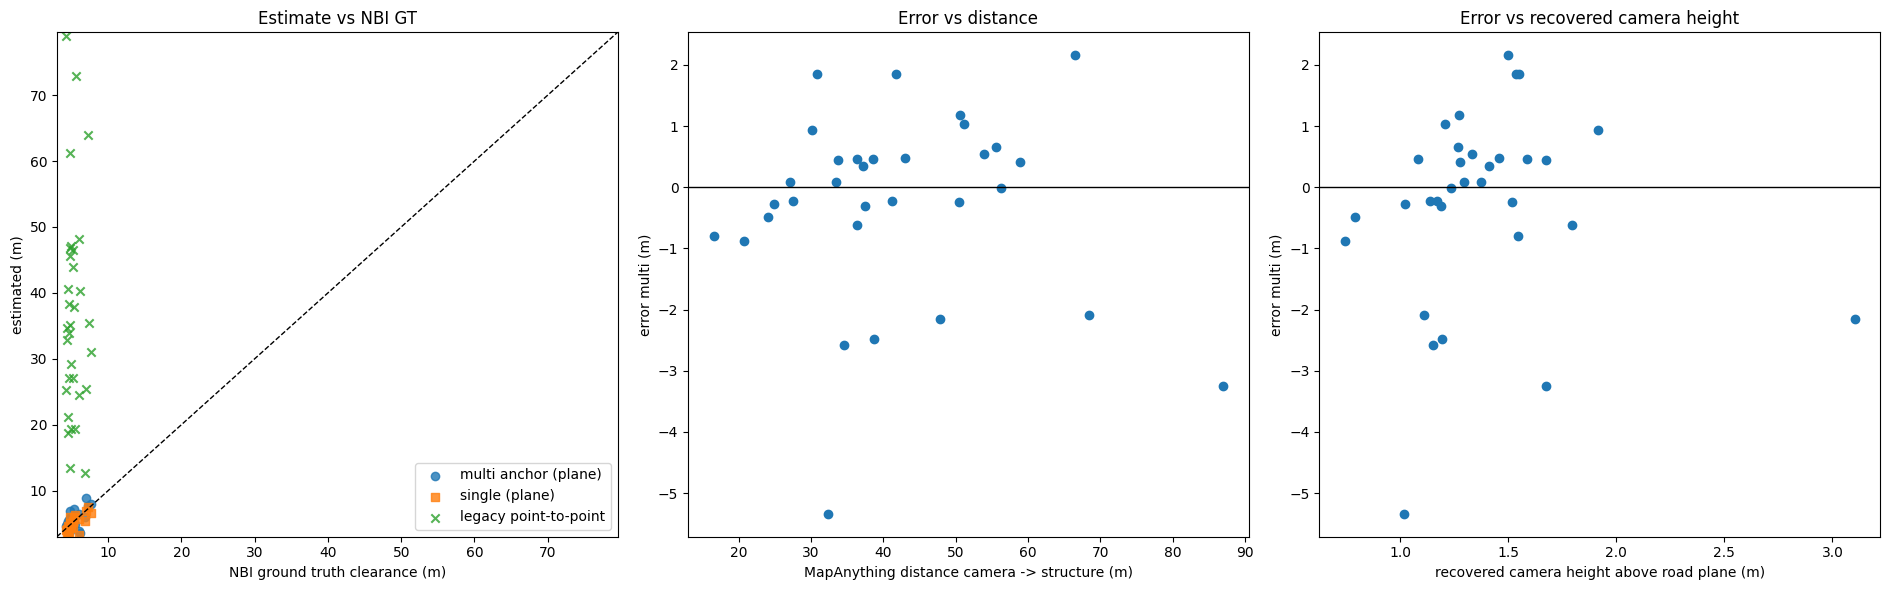

saved to /content/drive/MyDrive/capstone_clearance_nbi


In [26]:
# =========================
# 8. Results vs NBI ground truth
# =========================
QA_EXCLUDE = []   # add case_ids here after visual QA (wrong structure / camera not under the bridge)

recs = [json.loads(p.read_text()) for p in sorted(CASE_DIR.glob("*.json"))]
res = pd.DataFrame(recs)
res.to_csv(OUT_ROOT / "results_all_cases.csv", index=False)
print("status counts:"); display(res["status"].value_counts())

USE_AUTO_QC = True
ok = res[(res["status"] == "ok") & (~res["case_id"].isin(QA_EXCLUDE))].copy()
if USE_AUTO_QC and "qc_pass" in ok:
    print(f"auto-QC pass: {int(ok['qc_pass'].sum())} / {len(ok)}")
    ok = ok[ok["qc_pass"] == True]
ok["gt_ft"] = ok["gt_clearance_m"] * M2FT
METHODS = {
    "multi_clear_med_m": "Multi-view, anchor frame, plane (median)",
    "multi_allframes_med_m": "Multi-view, all frames, plane (median)",
    "multi_clear_p10_m": "Multi-view, anchor, plane (p10 ~ min clearance)",
    "single_clear_med_m": "Single-view anchor, plane (median)",
    "multi_legacy_point_m": "Legacy point-to-point (multi, anchor)",
    "single_legacy_point_m": "Legacy point-to-point (single)",
}
rows = []
for col, name in METHODS.items():
    if col not in ok: continue
    v = ok[[col, "gt_clearance_m"]].dropna()
    e = v[col] - v["gt_clearance_m"]
    rows.append({"method": name, "column": col, "n": len(v), "MAE_m": e.abs().mean(), "MAE_ft": e.abs().mean() * M2FT,
                 "RMSE_m": np.sqrt((e ** 2).mean()), "bias_m": e.mean(), "MAPE_%": (e.abs() / v["gt_clearance_m"]).mean() * 100,
                 "median_APE_%": (e.abs() / v["gt_clearance_m"]).median() * 100,
                 "within_0.3m_%": (e.abs() <= 0.3).mean() * 100, "within_0.5m_%": (e.abs() <= 0.5).mean() * 100,
                 "pearson_r": v[col].corr(v["gt_clearance_m"])})
metrics = pd.DataFrame(rows)
metrics.to_csv(OUT_ROOT / "metrics_vs_nbi.csv", index=False)
display(metrics.round(3))

show_cols = ["case_id", "feature_under", "facility_on", "service_on", "gt_clearance_m", "multi_clear_med_m", "multi_allframes_med_m",
             "single_clear_med_m", "multi_legacy_point_m", "multi_cam_height_m", "multi_struct_dist_m", "anchor_gps_d_m", "n_views", "anchor_year"]
tbl = ok[[c for c in show_cols if c in ok]].copy()
tbl["err_multi_m"] = tbl["multi_clear_med_m"] - tbl["gt_clearance_m"]
tbl["err_single_m"] = tbl["single_clear_med_m"] - tbl["gt_clearance_m"]
tbl = tbl.sort_values("gt_clearance_m")
tbl.to_csv(OUT_ROOT / "results_ok_cases_table.csv", index=False)
display(tbl.round(2))

fig, axes = plt.subplots(1, 3, figsize=(19, 6))
lim = [3, max(9, float(np.nanmax(ok[[c for c in METHODS if c in ok]].values)) + 0.5)]
for col, mk, lab in [("multi_clear_med_m", "o", "multi anchor (plane)"), ("single_clear_med_m", "s", "single (plane)"),
                     ("multi_legacy_point_m", "x", "legacy point-to-point")]:
    if col in ok: axes[0].scatter(ok["gt_clearance_m"], ok[col], marker=mk, label=lab, alpha=0.8)
axes[0].plot(lim, lim, "k--", lw=1); axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("NBI ground truth clearance (m)"); axes[0].set_ylabel("estimated (m)"); axes[0].legend(); axes[0].set_title("Estimate vs NBI GT")
e = ok["multi_clear_med_m"] - ok["gt_clearance_m"]
axes[1].scatter(ok["multi_struct_dist_m"], e); axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("MapAnything distance camera -> structure (m)"); axes[1].set_ylabel("error multi (m)"); axes[1].set_title("Error vs distance")
axes[2].scatter(ok["multi_cam_height_m"], e); axes[2].axhline(0, color="k", lw=1)
axes[2].set_xlabel("recovered camera height above road plane (m)"); axes[2].set_ylabel("error multi (m)"); axes[2].set_title("Error vs recovered camera height")
plt.tight_layout(); plt.savefig(VIS_DIR / "summary_scatter.png", dpi=130); plt.show()

with pd.ExcelWriter(OUT_ROOT / "clearance_vs_nbi_results.xlsx") as xw:
    metrics.to_excel(xw, sheet_name="metrics", index=False); tbl.to_excel(xw, sheet_name="ok_cases", index=False); res.to_excel(xw, sheet_name="all_cases", index=False)
print("saved to", OUT_ROOT)

In [27]:
# =========================
# 9. Contact sheet of all anchor overlays (for visual QA)
# =========================
ov_paths = sorted(VIS_DIR.glob("*_overlay.jpg"))
cols = 4
rows_n = math.ceil(len(ov_paths) / cols)
fig, axes = plt.subplots(rows_n, cols, figsize=(6 * cols, 4.6 * rows_n))
for ax in np.atleast_1d(axes).ravel():
    ax.axis("off")
for ax, p in zip(np.atleast_1d(axes).ravel(), ov_paths):
    ax.imshow(Image.open(p)); ax.set_title(p.stem.replace("_overlay", ""), fontsize=10)
plt.tight_layout(); plt.savefig(VIS_DIR / "contact_sheet.jpg", dpi=80); plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Results (run of 2026-10-09, L4, ~5 min for 80 bridges)

**A. Bridge under-clearance vs NBI 54B.** 80 bridges were searched. 38 had an anchor frame where Mask2Former found an overhead *Bridge* with road below it, and **32 passed auto-QC**. (41 had no visible structure: the NBI point is offset, or the sequence ran on the bridge instead of under it.)

| subset | method | n | MAE (m) | median AE (m) | bias (m) | MAPE | within 0.5 m |
|---|---|---|---|---|---|---|---|
| auto-QC, all cameras | multi-view (anchor) | 32 | 1.09 | 0.58 | −0.28 | 19.9 % | 47 % |
| auto-QC, all cameras | single-view | 30 | 0.92 | 0.43 | −0.69 | 16.8 % | 50 % |
| phone/GoPro (EXIF) only* | multi-view (anchor) | 24 | 0.77 | 0.47 | +0.28 | 14.6 % | 54 % |
| phone/GoPro (EXIF) only* | single-view | 24 | **0.65** | **0.32** | −0.43 | **12.4 %** | 54 % |
| no-EXIF (mostly wide-angle dashcam)* | multi-view | 8 | 2.05 | 2.12 | −1.94 | 36 % | 25 % |

\*The camera split was found **after** looking at the errors, so treat it as a diagnostic, not the headline number.

- The **legacy point-to-point** metric is unusable at bridge distance (10–130 m "clearances"). Its road point sits near the camera, not under the structure. The road-plane metric fixes this.
- Single-view is less biased in scale for phone cameras. Multi-view tends to over-estimate by ~0.3 m and has a few +1.9 m outliers.
- Main failure modes: fisheye/wide-angle dashcams (BlackVue overlays) are under-estimated by ~2 m. Some structures were > 60 m away. In a few cases the segmenter's *Bridge* mask covers walls or abutments, which the above-camera filter only partly removes.
- NBI 54B is the **minimum** clearance (lowest girder, often at a lane edge), while our number is the median over columns. A small positive bias is expected.

**B. Stop-sign size vs MUTCD (30"=0.762 m / 36"=0.914 m).** 25 signs, 15 measured (10 not found by the red + Vistas sign filter). Single-view median 0.88 m, MAE vs 30" 0.18 m (24 %), 71 % within 15 % of the nearest standard size. Multi-view median 0.94–0.99 m, which is biased high. Signs are only ~50–150 px wide, so the pixel width × depth / fx error is dominated by the mask edges.

## Notes / caveats
- NBI coordinates are the structure location, not the exact crossing point, so many Mapillary sequences near a bridge never pass under it. More candidate bridges → more usable cases.
- `recovered camera height` is a free check on MapAnything's metric scale. A car-mounted camera should sit ~1.0–2.0 m above the road plane; auto-QC uses 0.7–3.5 m.
- When SAM3 access is approved, replace the body of `sam3_segment()` (cell 5) and bump `RESULT_VERSION` in cell 1 to recompute.

In [28]:
# =========================
# 10. Second object type: STOP signs (MUTCD R1-1) -> sign width vs standard size
#     GT: MUTCD Table 2B-1 R1-1 = 30" x 30" (0.762 m) conventional road; 36" (0.914 m) multi-lane / expressway approaches
#     Mapillary map_features gives stop-sign locations + the images that see them.
# =========================
STOP_ROOT = OUT_ROOT / "stop_signs"; STOP_IMG = STOP_ROOT / "images"; STOP_RES = STOP_ROOT / "results"
for d in [STOP_ROOT, STOP_IMG, STOP_RES]:
    d.mkdir(parents=True, exist_ok=True)
STOP_GT_M = {"30in": 0.762, "36in": 0.914}
N_STOP_CASES = 25
STOP_D_RANGE = (5, 28)          # camera -> sign distance (m)
SIGN_FRONT_IDS = _ids(lambda n: "traffic sign (front)" in n or n == "traffic sign")
print("sign classes:", [ID2LABEL[i] for i in SIGN_FRONT_IDS])

STOP_CASES_PATH = STOP_ROOT / "stop_cases.json"
stop_cases = json.loads(STOP_CASES_PATH.read_text()) if STOP_CASES_PATH.exists() else []
rng = np.random.default_rng(SEED)
# random ~1 km tiles over Chicago city + inner suburbs (residential grids have many all-way stops)
tiles = [(lon, lat) for lon, lat in zip(rng.uniform(-87.95, -87.58, 120), rng.uniform(41.70, 42.05, 120))]
seen_feat = {c["feature_id"] for c in stop_cases}
for lon, lat in tiles:
    if len(stop_cases) >= N_STOP_CASES:
        break
    box = [lon - 0.006, lat - 0.0045, lon + 0.006, lat + 0.0045]
    try:
        feats = mapillary_get("https://graph.mapillary.com/map_features",
                              {"bbox": ",".join(f"{v:.6f}" for v in box), "object_values": "regulatory--stop--g1",
                               "fields": "id,object_value,geometry,images", "limit": 200}).get("data", [])
    except Exception as e:
        print("map_features failed:", e); continue
    for f in feats[:6]:
        if len(stop_cases) >= N_STOP_CASES or f["id"] in seen_feat:
            continue
        seen_feat.add(f["id"])
        slon, slat = f["geometry"]["coordinates"][:2]
        img_ids = [i["id"] for i in (f.get("images") or {}).get("data", [])][:25]
        rows = []
        for iid in img_ids:
            try:
                m = mapillary_get(f"https://graph.mapillary.com/{iid}", {"fields": IMG_FIELDS})
            except Exception:
                continue
            if m.get("camera_type") in ["spherical", "equirectangular", "fisheye"] or not m.get("thumb_2048_url"):
                continue
            x, y = _xy(m.get("computed_geometry") or m.get("geometry"))
            h = m.get("computed_compass_angle", m.get("compass_angle"))
            if np.isnan(x) or h is None:
                continue
            d = haversine_m(x, y, slon, slat)
            if STOP_D_RANGE[0] <= d <= STOP_D_RANGE[1] and ang_diff(h, bearing_deg(x, y, slon, slat)) <= 40:
                rows.append({"image_id": str(m["id"]), "sequence": m.get("sequence"), "url": m["thumb_2048_url"], "d_m": d,
                             "captured_at": m.get("captured_at")})
        if not rows:
            continue
        df = pd.DataFrame(rows)
        seq = df.sequence.value_counts().index[0]
        g = df[df.sequence == seq].sort_values("d_m", ascending=False).head(MAX_VIEWS)
        if len(g) < 2:
            continue
        cid = f"stop_{f['id']}"
        cdir = STOP_IMG / cid; cdir.mkdir(exist_ok=True)
        frames, size = [], None
        for k, r in enumerate(g.itertuples()):
            p = cdir / f"{k:02d}_{r.image_id}.jpg"
            if not p.exists():
                im = download_img(r.url, p, size=size)
            size = size or Image.open(p).size
            frames.append({"image_id": r.image_id, "d_m": float(r.d_m), "local_path": str(p), "captured_at": r.captured_at})
        stop_cases.append({"case_id": cid, "feature_id": f["id"], "lon": slon, "lat": slat, "sequence": seq, "frames": frames})
        STOP_CASES_PATH.write_text(json.dumps(stop_cases, indent=1, default=str))
        print(f"[{len(stop_cases):02d}] {cid}  views={len(frames)}  d={[round(fr['d_m']) for fr in frames]}")
print("stop-sign cases:", len(stop_cases))

sign classes: ['Traffic Sign (Front)']
[11] stop_7462794873838085  views=4  d=[27, 26, 24, 21]
[12] stop_418244051260047  views=3  d=[22, 16, 12]
[13] stop_418244054593380  views=3  d=[24, 19, 11]
[14] stop_418244064593379  views=4  d=[22, 16, 11, 8]
[15] stop_1012328850318922  views=4  d=[26, 22, 18, 15]
[16] stop_1012328866985587  views=3  d=[22, 19, 15]
[17] stop_1112856770018450  views=4  d=[27, 19, 13, 9]
[18] stop_1169701390711029  views=4  d=[15, 13, 12, 12]
[19] stop_1708779133223418  views=2  d=[15, 13]
[20] stop_322266220891073  views=3  d=[24, 16, 11]
[21] stop_338034422327126  views=4  d=[27, 19, 12, 7]
[22] stop_338034425660459  views=4  d=[25, 19, 13, 9]
[23] stop_459141723253726  views=4  d=[28, 19, 16, 10]
[24] stop_815907530452227  views=2  d=[23, 12]
[25] stop_812226880821983  views=3  d=[22, 15, 11]
stop-sign cases: 25


[01] stop_1144279403285728 status=no_sign_found size=None
[02] stop_1144279459952389 status=no_sign_found size=None
[03] stop_8722247321136147 status=no_sign_found size=None
[04] stop_1118992076014492 status=ok size=1.0261479824863158
[05] stop_404177115837202 status=no_sign_found size=None
[06] stop_1578774656311185 status=ok size=0.8245517320784026
[07] stop_7915141545184238 status=ok size=1.0657341011949613
[08] stop_7462794847171421 status=no_sign_found size=None
[09] stop_7462794853838087 status=no_sign_found size=None
[10] stop_7462794863838086 status=no_sign_found size=None
[11] stop_7462794873838085 status=no_sign_found size=None
[12] stop_418244051260047 status=ok size=1.510979651731205
[13] stop_418244054593380 status=ok size=0.8946897326908785
[14] stop_418244064593379 status=ok size=1.5139214909678556
[15] stop_1012328850318922 status=ok size=1.068760102083576
[16] stop_1012328866985587 status=ok size=0.9882722850580652
[17] stop_1112856770018450 status=ok size=0.9336451037

,count
status,
ok,15
no_sign_found,10


,method,n,median_est_m,MAE_vs_30in_m,MAPE_vs_30in_%,MAE_vs_nearest_std_m,within_15%_of_30or36_%
0,multi_best_frame_size_m,15,0.986,0.261,34.219,0.144,66.667
1,multi_size_med_m,15,0.945,0.222,29.165,0.102,66.667
2,single_size_m,14,0.876,0.182,23.829,0.106,71.429


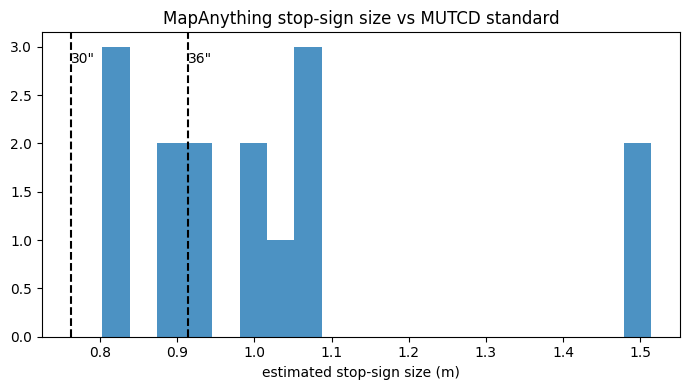

In [29]:
# =========================
# 11. Stop-sign width from MapAnything: width_m = sign_width_px * depth / fx  (and 3D left-right edge distance)
# =========================
def find_stop_sign(img):
    """Largest red, roughly square 'Traffic Sign (Front)' component (Mask2Former Vistas)."""
    lab = semantic_labels(img)
    sign = np.isin(lab, SIGN_FRONT_IDS)
    if not sign.any():
        return None
    rgb = np.asarray(img).astype(np.int32)
    red = (rgb[..., 0] > 90) & (rgb[..., 0] > 1.5 * rgb[..., 1]) & (rgb[..., 0] > 1.3 * rgb[..., 2])
    cc, n = ndimage.label(sign)
    best, best_s = None, 0
    for k in range(1, n + 1):
        m = cc == k
        area = int(m.sum())
        if area < 120:
            continue
        ys, xs = np.where(m)
        w, h = xs.max() - xs.min() + 1, ys.max() - ys.min() + 1
        red_frac = float(red[m].mean())
        if red_frac < 0.35 or not (0.7 <= w / h <= 1.4):
            continue
        s = area * red_frac
        if s > best_s:
            best, best_s = {"mask": m, "w_px": int(w), "h_px": int(h), "red_frac": red_frac, "bbox": [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]}, s
    return best

def sign_width_estimate(ma_raw_pred, ma, sign, img_size):
    W0, H0 = img_size
    pts_cam = squeeze_b(ma_raw_pred["pts3d_cam"]).astype(np.float32) if "pts3d_cam" in ma_raw_pred else None
    K = squeeze_b(ma_raw_pred["intrinsics"]).astype(np.float64)
    H, W = ma["pts3d"].shape[:2]
    m_small = resize_mask(sign["mask"], (H, W))
    if m_small.sum() < 2:
        m_small = ndimage.binary_dilation(m_small, iterations=1) if m_small.any() else m_small
    ok = m_small & ma["loose"]
    if ok.sum() == 0 or pts_cam is None:
        return None
    z = float(np.median(pts_cam[ok][:, 2]))
    fx0 = K[0, 0] * W0 / W                     # focal length rescaled to the original image width
    width_m = sign["w_px"] * z / fx0
    height_m = sign["h_px"] * z / (K[1, 1] * H0 / H)
    return {"depth_m": z, "width_m": width_m, "height_m": height_m, "size_m": 0.5 * (width_m + height_m), "n_pts": int(ok.sum())}

def run_mapanything_raw(paths):
    views = load_images(list(paths))
    with torch.inference_mode():
        preds = ma_model.infer(views, memory_efficient_inference=True, minibatch_size=1, use_amp=DEVICE == "cuda",
                               amp_dtype="bf16", apply_mask=False, mask_edges=True, confidence_percentile=50)
    return preds

stop_recs = []
for i, sc in enumerate(json.loads(STOP_CASES_PATH.read_text())):
    rp = STOP_RES / f"{sc['case_id']}.json"
    if rp.exists() and not FORCE_RERUN:
        stop_recs.append(json.loads(rp.read_text())); continue
    rec = {"case_id": sc["case_id"], "lon": sc["lon"], "lat": sc["lat"], "n_views": len(sc["frames"])}
    try:
        paths = [f["local_path"] for f in sc["frames"]]
        imgs = [Image.open(p).convert("RGB") for p in paths]
        signs = [find_stop_sign(im) for im in imgs]
        rec["n_frames_sign_found"] = int(sum(s is not None for s in signs))
        if rec["n_frames_sign_found"] == 0:
            rec["status"] = "no_sign_found"
        else:
            multi = run_mapanything_raw(paths)
            ests = []
            for k, (pred, sg) in enumerate(zip(multi, signs)):
                if sg is None:
                    continue
                e = sign_width_estimate(pred, unpack_ma(pred), sg, imgs[k].size)
                if e: ests.append({**e, "frame": k, "w_px": sg["w_px"]})
            k_best = int(np.argmax([s["w_px"] if s else -1 for s in signs]))   # largest sign in image = closest frame
            single_pred = run_mapanything_raw([paths[k_best]])[0]
            e_single = sign_width_estimate(single_pred, unpack_ma(single_pred), signs[k_best], imgs[k_best].size)
            if ests:
                rec.update({"multi_size_med_m": float(np.median([e["size_m"] for e in ests])),
                            "multi_width_med_m": float(np.median([e["width_m"] for e in ests])),
                            "multi_best_frame_size_m": next((e["size_m"] for e in ests if e["frame"] == k_best), np.nan),
                            "depth_best_m": next((e["depth_m"] for e in ests if e["frame"] == k_best), np.nan),
                            "sign_px_best": signs[k_best]["w_px"]})
            if e_single:
                rec["single_size_m"] = e_single["size_m"]
            rec["status"] = "ok" if ests else "no_depth"
            # overlay of the best frame
            im = imgs[k_best].copy(); dr = ImageDraw.Draw(im); x1, y1, x2, y2 = signs[k_best]["bbox"]
            dr.rectangle([x1 - 4, y1 - 4, x2 + 4, y2 + 4], outline=(0, 255, 255), width=5)
            dr.text((x1, max(0, y1 - 45)), f"{rec.get('multi_best_frame_size_m', float('nan')):.2f} m (GT 0.76/0.91)", fill=(0, 255, 255), font=FONT)
            im.save(STOP_ROOT / f"{sc['case_id']}_overlay.jpg", quality=85)
            del multi; gc.collect(); torch.cuda.empty_cache()
    except Exception as e:
        rec["status"] = f"error: {type(e).__name__}: {e}"
    rp.write_text(json.dumps(rec, indent=1, default=str)); stop_recs.append(rec)
    print(f"[{i+1:02d}] {rec['case_id']} status={rec['status']} size={rec.get('multi_best_frame_size_m')}")

sres = pd.DataFrame(stop_recs)
sres.to_csv(STOP_ROOT / "stop_sign_results.csv", index=False)
sok = sres[sres.status == "ok"].copy()
rows = []
for col in ["multi_best_frame_size_m", "multi_size_med_m", "single_size_m"]:
    if col not in sok: continue
    v = sok[col].dropna()
    if len(v) == 0: continue
    e30 = v - STOP_GT_M["30in"]
    near = np.where((v - 0.762).abs() <= (v - 0.914).abs(), 0.762, 0.914)
    rows.append({"method": col, "n": len(v), "median_est_m": v.median(), "MAE_vs_30in_m": e30.abs().mean(),
                 "MAPE_vs_30in_%": (e30.abs() / 0.762).mean() * 100, "MAE_vs_nearest_std_m": np.abs(v - near).mean(),
                 "within_15%_of_30or36_%": (np.abs(v - near) / near <= 0.15).mean() * 100})
stop_metrics = pd.DataFrame(rows); stop_metrics.to_csv(STOP_ROOT / "stop_sign_metrics.csv", index=False)
display(sres["status"].value_counts()); display(stop_metrics.round(3))
plt.figure(figsize=(7, 4))
plt.hist(sok["multi_best_frame_size_m"].dropna(), bins=20, alpha=0.8)
for v, l in [(0.762, '30"'), (0.914, '36"')]:
    plt.axvline(v, color="k", ls="--"); plt.text(v, plt.ylim()[1] * 0.9, l)
plt.xlabel("estimated stop-sign size (m)"); plt.title("MapAnything stop-sign size vs MUTCD standard"); plt.tight_layout()
plt.savefig(STOP_ROOT / "stop_sign_hist.png", dpi=120); plt.show()

,subset,method,n,MAE_m,median_AE_m,bias_m,MAPE_%,within_0.5m_%,within_10%_%
0,auto-QC pass (all cameras),multi_clear_med_m,32,1.091,0.582,-0.278,19.918,46.875,40.625
1,auto-QC pass (all cameras),multi_allframes_med_m,32,1.105,0.547,-0.273,20.108,46.875,40.625
2,auto-QC pass (all cameras),single_clear_med_m,30,0.925,0.426,-0.693,16.764,50.000,50.000
3,"auto-QC pass, phone/GoPro (EXIF) only",multi_clear_med_m,24,0.771,0.468,0.276,14.570,54.167,50.000
4,"auto-QC pass, phone/GoPro (EXIF) only",multi_allframes_med_m,24,0.734,0.470,0.338,13.915,54.167,50.000
5,"auto-QC pass, phone/GoPro (EXIF) only",single_clear_med_m,24,0.650,0.317,-0.429,12.362,54.167,54.167
6,no-EXIF camera (mostly dashcam) only,multi_clear_med_m,8,2.052,2.120,-1.941,35.964,25.000,12.500
7,no-EXIF camera (mostly dashcam) only,multi_allframes_med_m,8,2.218,2.026,-2.105,38.686,25.000,12.500
8,no-EXIF camera (mostly dashcam) only,single_clear_med_m,6,2.025,1.638,-1.752,34.376,33.333,33.333


,cam_make,cam_model,n
0,Apple,iPadMini4,5
1,Apple,iPhone 8,1
2,Apple,iPhone5,3
3,Apple,iPhone5S,1
4,Apple,"iPhone6,1",1
5,Apple,iPhone6Plus,1
6,Apple,iPhone6S,1
7,Apple,iPhone6SPlus,1
8,Apple,iPhone7,4
9,Apple,"iPhone7,2",1


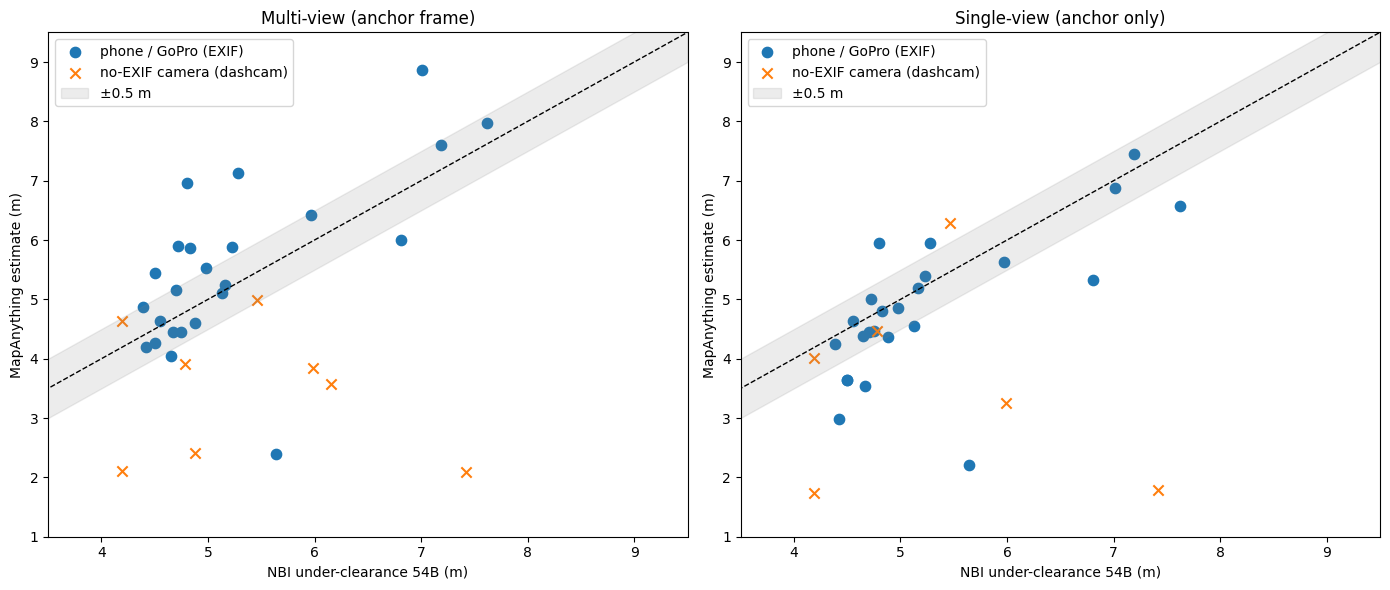

In [31]:
# =========================
# 8b. Error breakdown by camera (Mapillary make/model of the anchor frame) + final bridge figure
#     Frames without camera EXIF are mostly wide-angle dashcams (strong distortion); MapAnything assumes near-pinhole input.
#     NOTE: this split was identified after looking at errors (post hoc) -> report it as a diagnostic, not as the headline metric.
# =========================
cam_cache = OUT_ROOT / "anchor_camera_info.json"
cam_info = json.loads(cam_cache.read_text()) if cam_cache.exists() else {}
for iid in res.loc[res["status"] == "ok", "anchor_image_id"].astype(str):
    if iid not in cam_info:
        try:
            m = mapillary_get(f"https://graph.mapillary.com/{iid}", {"fields": "make,model,camera_type,camera_parameters,width,height"})
            cam_info[iid] = {k: m.get(k) for k in ["make", "model", "camera_type", "camera_parameters", "width", "height"]}
        except Exception as e:
            cam_info[iid] = {"make": None}
cam_cache.write_text(json.dumps(cam_info, indent=1))
res["anchor_image_id"] = res["anchor_image_id"].astype(str)
res["cam_make"] = res["anchor_image_id"].map(lambda i: (cam_info.get(i) or {}).get("make") or "unknown")
res["cam_model"] = res["anchor_image_id"].map(lambda i: (cam_info.get(i) or {}).get("model") or "unknown")
# Mapillary make/model come from EXIF; uploads without it are mostly wide-angle dashcams (e.g. BlackVue overlays visible in frames)
res["wide_angle_dashcam"] = res["cam_make"].astype(str).str.lower().isin(["none", "unknown", "", "nan"])
res.to_csv(OUT_ROOT / "results_all_cases.csv", index=False)

qc = res[(res["status"] == "ok") & (res.get("qc_pass", True) == True) & (~res["case_id"].isin(QA_EXCLUDE))].copy()
def summarize(df, label):
    out = []
    for col in ["multi_clear_med_m", "multi_allframes_med_m", "single_clear_med_m"]:
        v = df[[col, "gt_clearance_m"]].dropna(); e = v[col] - v["gt_clearance_m"]
        if len(v) == 0: continue
        out.append({"subset": label, "method": col, "n": len(v), "MAE_m": e.abs().mean(), "median_AE_m": e.abs().median(),
                    "bias_m": e.mean(), "MAPE_%": (e.abs() / v["gt_clearance_m"]).mean() * 100,
                    "within_0.5m_%": (e.abs() <= 0.5).mean() * 100, "within_10%_%": ((e.abs() / v["gt_clearance_m"]) <= 0.10).mean() * 100})
    return out
breakdown = pd.DataFrame(summarize(qc, "auto-QC pass (all cameras)")
                         + summarize(qc[~qc["wide_angle_dashcam"]], "auto-QC pass, phone/GoPro (EXIF) only")
                         + summarize(qc[qc["wide_angle_dashcam"]], "no-EXIF camera (mostly dashcam) only"))
breakdown.to_csv(OUT_ROOT / "metrics_breakdown.csv", index=False)
display(breakdown.round(3))
display(qc.groupby(["cam_make", "cam_model"]).size().rename("n").reset_index())

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, col, ttl in [(ax[0], "multi_clear_med_m", "Multi-view (anchor frame)"), (ax[1], "single_clear_med_m", "Single-view (anchor only)")]:
    for flag, mk, lab in [(False, "o", "phone / GoPro (EXIF)"), (True, "x", "no-EXIF camera (dashcam)")]:
        s = qc[qc["wide_angle_dashcam"] == flag]
        a.scatter(s["gt_clearance_m"], s[col], marker=mk, s=55, label=lab)
    a.plot([1, 9.5], [1, 9.5], "k--", lw=1); a.fill_between([1, 9.5], [0.5, 9], [1.5, 10], color="gray", alpha=0.15, label="±0.5 m")
    a.set_xlim(3.5, 9.5); a.set_ylim(1, 9.5); a.set_xlabel("NBI under-clearance 54B (m)"); a.set_ylabel("MapAnything estimate (m)")
    a.set_title(ttl); a.legend(loc="upper left")
plt.tight_layout(); plt.savefig(VIS_DIR / "bridge_estimate_vs_nbi_by_camera.png", dpi=130); plt.show()